# Maliar-Maliar-Winant Deep Learning Method: RBC Warm-up in Julia

This notebook uses the Euler-equation deep learning method in Maliar, Maliar, and Winant (2021) to solve a small stochastic RBC model. A neural network approximates the consumption policy, and its parameters are trained by minimizing simulated Euler-equation residuals with `Flux.gradient` and Adam. We use CRRA utility with curvature $\gamma=2$ and standard partial depreciation; because no closed-form policy is available, the learned policy is compared with VFI and EGM numerical solutions.

## 1) RBC Model

A representative household chooses consumption and next-period capital:

$$
\max_{\{c_t,k_{t+1}\}} E_0 \sum_{t=0}^{\infty}\beta^t \frac{c_t^{1-\gamma}-1}{1-\gamma}
$$

subject to

$$
c_t+k_{t+1}=e^{z_t}k_t^\alpha+(1-\delta)k_t,
$$

$$
z_{t+1}=\rho_z z_t+\sigma_z\epsilon_{t+1}, \qquad \epsilon_{t+1}\sim N(0,1).
$$

This notebook uses CRRA utility with standard partial depreciation:

$$
\gamma=2, \qquad \delta=0.08.
$$

The Euler equation is

$$
1
=
\beta E_t\left[\left(\frac{c_{t+1}}{c_t}\right)^{-\gamma}
\left(\alpha e^{z_{t+1}}k_{t+1}^{\alpha-1}+1-\delta\right)\right].
$$

Maliar et al. turn this condition into a loss:

$$
\mathcal L(\theta)=E_{k,z}\left[\left(E_{\epsilon}[q(k,z,\epsilon;\theta)\mid k,z]\right)^2\right],
$$

where $q$ is the one-shock Euler residual implied by a neural-network policy rule. Section 5 evaluates this objective with the paper's two-shock AiO operator. No closed-form policy is available under this calibration, so Section 7 compares the neural-network policy with VFI and EGM numerical solutions.

## 2) Julia Setup

The notebook activates the local Julia project and uses `Flux.gradient` for automatic differentiation of the Euler-equation loss.

In [5]:
using Pkg

function find_project_root(start_dir=pwd())
    dir = abspath(start_dir)
    while true
        if isfile(joinpath(dir, "Project.toml"))
            return dir
        end
        parent = dirname(dir)
        parent == dir && error("Could not find Project.toml from $(start_dir)")
        dir = parent
    end
end

project_root = find_project_root()
Pkg.activate(project_root)

using Random
using LinearAlgebra
using Statistics
using Printf
using Flux
using Plots

include(joinpath(project_root, "src", "NetworkDiagram.jl"))
include(joinpath(project_root, "src", "RBCNumericalSolvers.jl"))
using .RBCNumericalSolvers

  Activating project at `c:\Users\86132\Desktop\Yuxuan ZHAO\minnesota\Research\DeepLearningMacro`


## 3) Calibration and Steady State

The deterministic steady state satisfies

$$
\frac{1}{\beta}=\alpha K^{\alpha-1}+1-\delta.
$$

In [6]:
Base.@kwdef struct RBCParams
    beta::Float64 = 0.96
    gamma::Float64 = 2.0
    alpha::Float64 = 0.36
    delta::Float64 = 0.08
    rho_z::Float64 = 0.95
    sigma_z::Float64 = 0.007

    hidden::Int = 8 # number of hidden units in the neural network
    xi_min::Float64 = 0.02
    xi_max::Float64 = 0.98
end

function steady_state(p::RBCParams)
    K = ((1 / p.beta - (1 - p.delta)) / p.alpha)^(1 / (p.alpha - 1))
    Y = K^p.alpha
    C = Y - p.delta * K
    W = Y + (1 - p.delta) * K
    xi = C / W
    return (; K, Y, C, W, xi)
end

par = RBCParams()
nk = 1000              # capital-grid points for VFI and EGM
nz = 5                 # productivity states for VFI and EGM
k_min_ratio = 0.55     # common lower bound for NN sampling, VFI, and EGM
k_max_ratio = 1.60     # common upper bound for NN sampling, VFI, and EGM
vfi_tol = 1e-7         # tolerance for the value-function sup norm
egm_tol = 1e-8         # tolerance for the capital-policy sup norm
warmup_nk = 20         # smaller grid used only to compile solver code paths
warmup_nz = 2
ss = steady_state(par)

@printf("K_ss = %.4f\n", ss.K)
@printf("C_ss = %.4f\n", ss.C)
@printf("steady-state consumption/resource share xi_ss = %.4f\n", ss.xi)

K_ss = 5.4468
C_ss = 1.4051
steady-state consumption/resource share xi_ss = 0.2051


## 4) Neural-Network Policy Rule

We parameterize the policy by a consumption share:

$$
\xi(k,z;\theta)\in(\xi_{\min},\xi_{\max})=(0.02,0.98).
$$

Given resources

$$
w(k,z)=e^zk^\alpha+(1-\delta)k,
$$

the implied policy is

$$
c(k,z;\theta)=\xi(k,z;\theta)w(k,z),\qquad
k'(k,z;\theta)=\left[1-\xi(k,z;\theta)\right]w(k,z).
$$

Hence feasibility holds by construction:

$$
c>0,\qquad k'>0,\qquad c+k'=w(k,z).
$$

The neural-network input is the normalized state

$$
x(k,z)=\begin{bmatrix}
\log\left(k/K_{ss}\right)\\
z/\left(3\sigma_{z,\infty}\right)
\end{bmatrix},
\qquad
\sigma_{z,\infty}=\frac{\sigma_z}{\sqrt{1-\rho_z^2}}.
$$

With one hidden layer of $H=8$ neurons,

$$
s_1=W_1x+b_1,\qquad h=\tanh(s_1),\qquad h\in(-1,1)^8,
$$

where the hidden-layer activation is

$$
\tanh(s)=\frac{e^s-e^{-s}}{e^s+e^{-s}}=\frac{e^{2s}-1}{e^{2s}+1}.
$$

The output layer maps $h$ into one scalar share:

$$
a=W_2h+b_2,\qquad \sigma(a)=\frac{1}{1+e^{-a}},
$$

$$
\xi(k,z;\theta)=\xi_{\min}+(\xi_{\max}-\xi_{\min})\sigma(a(k,z;\theta)).
$$

Thus the network input is $x\in\mathbb R^2$, the network output is the scalar $\xi\in(0.02,0.98)$, and the economic objects are $c$ and $k'$. The bounds avoid the unstable endpoints $c\approx 0$ and $k'\approx 0$.

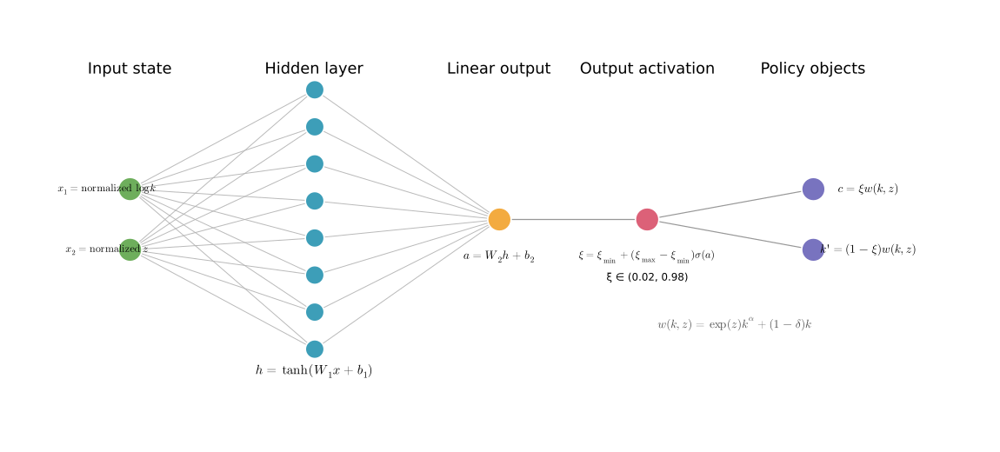

In [7]:
plot_policy_network_diagram(hidden=par.hidden, xi_min=par.xi_min, xi_max=par.xi_max)

In [8]:
function sigmoid_stable(x)
    if x >= 0
        q = exp(-x)
        return 1 / (1 + q)
    else
        q = exp(x)
        return q / (1 + q)
    end
end

logit(x) = log(x / (1 - x))

function nparams(p::RBCParams)
    H = p.hidden
    return 2 * H + H + H + 1       # W1, b1, W2, b2
end

function unpack(theta, p::RBCParams)
    H = p.hidden
    i = 1
    W1 = reshape(theta[i:(i + 2H - 1)], H, 2)
    i += 2H
    b1 = theta[i:(i + H - 1)]
    i += H
    W2 = theta[i:(i + H - 1)]
    i += H
    b2 = theta[i]
    return W1, b1, W2, b2
end

function init_theta(rng::AbstractRNG, p::RBCParams, ss)
    theta = 0.05 .* randn(rng, nparams(p))
    q = (ss.xi - p.xi_min) / (p.xi_max - p.xi_min)
    theta[end] = logit(q)
    return theta
end

function normalize_state(k, z, p::RBCParams, ss)
    zsd = p.sigma_z / sqrt(1 - p.rho_z^2)
    return [log(k / ss.K), z / (3zsd)]
end

function policy_share(theta, k, z, p::RBCParams, ss)
    W1, b1, W2, b2 = unpack(theta, p)
    x = normalize_state(k, z, p, ss)
    h = tanh.(W1 * x .+ b1)
    raw = dot(W2, h) + b2
    return p.xi_min + (p.xi_max - p.xi_min) * sigmoid_stable(raw)
end

resources(k, z, p::RBCParams) = exp(z) * k^p.alpha + (1 - p.delta) * k
gross_return(k, z, p::RBCParams) = p.alpha * exp(z) * k^(p.alpha - 1) + 1 - p.delta

function policy_ck(theta, k, z, p::RBCParams, ss)
    xi = policy_share(theta, k, z, p, ss)
    w = resources(k, z, p)
    c = max(xi * w, 1e-10)
    kp = max(w - c, 1e-10)
    return c, kp, xi
end

rng = MersenneTwister(1234)
theta = init_theta(rng, par, ss)

c0, kp0, xi0 = policy_ck(theta, ss.K, 0.0, par, ss)
@printf("Initial NN at steady state: c = %.4f, k' = %.4f, xi = %.4f\n", c0, kp0, xi0)

Initial NN at steady state: c = 1.4005, k' = 5.4514, xi = 0.2044


## 5) Euler Residual as the Loss

### 5.1 The population objective

Fix a current state $s=(k,z)$. The neural network determines current consumption and next-period capital,

$$
c=c(k,z;\theta),
\qquad
k'=k'(k,z;\theta).
$$

For one possible future innovation $\epsilon$, define

$$
z'(\epsilon)=\rho_z z+\sigma_z\epsilon,
\qquad
c'(\epsilon)=c(k',z'(\epsilon);\theta),
$$

and the one-draw Euler residual

$$
q(k,z,\epsilon;\theta)
=
\beta
\frac{u'(c'(\epsilon))}{u'(c)}
\left[\alpha e^{z'(\epsilon)}(k')^{\alpha-1}+1-\delta\right]
-1.
$$

The stochastic Euler equation does **not** require $q=0$ for every realized shock. It requires the conditional mean to be zero:

$$
\bar R(k,z;\theta)
\equiv
E_{\epsilon}[q(k,z,\epsilon;\theta)\mid k,z]
=0.
$$

Because the network must satisfy this restriction over many current states, define the population loss

$$
\boxed{
\mathcal L(\theta)
=E_{k,z}\left[\bar R(k,z;\theta)^2\right].
}
$$

The inner expectation integrates over possible future shocks conditional on the current state. The outer expectation averages the squared Euler error over the current-state distribution used for training.

### 5.2 Why one shock squared is not the target

With one draw $\epsilon_1$, $q_1=q(k,z,\epsilon_1;\theta)$ is an unbiased estimate of $\bar R(k,z;\theta)$. However, $q_1^2$ is not an unbiased estimate of $\bar R^2$:

$$
E_{\epsilon_1}[q_1^2\mid k,z]
=\bar R(k,z;\theta)^2
+\operatorname{Var}_{\epsilon}(q\mid k,z).
$$

Thus a one-shock squared loss adds an unwanted conditional-variance penalty.

### 5.3 The all-in-one expectation operator

The AiO method draws two conditionally independent future shocks for the same current state,

$$
\epsilon_1,\epsilon_2\overset{iid}{\sim}N(0,1),
\qquad
\epsilon_1\perp\epsilon_2\mid(k,z),
$$

and computes $q_1=q(k,z,\epsilon_1;\theta)$ and $q_2=q(k,z,\epsilon_2;\theta)$. Independence implies

$$
\begin{aligned}
E_{\epsilon_1,\epsilon_2}[q_1q_2\mid k,z]
&=E_{\epsilon_1}[q_1\mid k,z]
  E_{\epsilon_2}[q_2\mid k,z]\\
&=\bar R(k,z;\theta)^2.
\end{aligned}
$$

Therefore the nested objective can be written as one joint expectation:

$$
\boxed{
\mathcal L(\theta)
=E_{k,z,\epsilon_1,\epsilon_2}
\left[q(k,z,\epsilon_1;\theta)q(k,z,\epsilon_2;\theta)\right].
}
$$

This is the AiO idea: simulate the current state and the two future shocks together, then approximate the entire objective with one Monte Carlo average.

### 5.4 Mini-batch estimator

The index $i$ labels a current-state observation; it does **not** label repeated shock draws at one fixed state. For every $i=1,\ldots,B$, the simulation first draws one current state $(k_i,z_i)$ and then, conditional on that same state, draws one independent future-shock pair

$$
\epsilon_{1,i},\epsilon_{2,i}\overset{iid}{\sim}N(0,1).
$$

Thus one mini-batch is

$$
\mathcal B
=\left\{(k_i,z_i,\epsilon_{1,i},\epsilon_{2,i})\right\}_{i=1}^B.
$$

It contains $B$ sampled current states and $2B$ future-shock values: one shock pair for each state. The computed loss is

$$
\boxed{
\widehat{\mathcal L}_{AiO}(\theta)
=\frac{1}{B}\sum_{i=1}^B
q(k_i,z_i,\epsilon_{1,i};\theta)
q(k_i,z_i,\epsilon_{2,i};\theta).
}
$$

The same average performs two Monte Carlo tasks:

$$
\underbrace{(k_i,z_i)_{i=1}^B}_{\text{approximates the outer }E_{k,z}}
\qquad\text{and}\qquad
\underbrace{((\epsilon_{1,i},\epsilon_{2,i}))_{i=1}^B}_{\text{constructs one AiO cross-product for each state}}.
$$

If we instead fixed one $(k,z)$ and drew $B$ shock pairs there, we would estimate only $\bar R(k,z;\theta)^2$ for that particular state and would not approximate the outer expectation over states.

The estimator satisfies $E[\widehat{\mathcal L}_{AiO}(\theta)]=\mathcal L(\theta)$. A finite-batch estimate can be noisy or even negative because individual cross-products can be negative; the population objective remains nonnegative. Repeatedly drawing fresh batches gives Adam stochastic gradients of the intended population loss.

In [9]:
uprime(c, p::RBCParams) = c^(-p.gamma)

function euler_draw_residual(theta, k, z, eps_next, p::RBCParams, ss)
    c, kp, _ = policy_ck(theta, k, z, p, ss)
    zp = p.rho_z * z + p.sigma_z * eps_next
    cp, _, _ = policy_ck(theta, kp, zp, p, ss)
    retp = gross_return(kp, zp, p)
    return p.beta * uprime(cp, p) * retp / uprime(c, p) - 1
end

function aio_euler_loss(theta, k_batch, z_batch, eps_1_batch, eps_2_batch, p::RBCParams, ss)
    s = 0.0
    for i in eachindex(k_batch)
        # Same current state, two independent future-shock branches.
        r_1 = euler_draw_residual(theta, k_batch[i], z_batch[i], eps_1_batch[i], p, ss)
        r_2 = euler_draw_residual(theta, k_batch[i], z_batch[i], eps_2_batch[i], p, ss)
        # E[r_1 * r_2 | k,z] equals the squared conditional Euler residual.
        s += r_1 * r_2
    end
    return s / length(k_batch)
end

test_k = fill(ss.K, 10)
test_z = zeros(10)
test_eps_1 = randn(rng, 10)
test_eps_2 = randn(rng, 10)
@printf("Initial AiO Euler objective near steady state = %.6e\n", aio_euler_loss(theta, test_k, test_z, test_eps_1, test_eps_2, par, ss))

Initial AiO Euler objective near steady state = 1.589670e-06


## 6) Simulation and Stochastic Training

The key training principle is that the Euler equation is a **state-by-state conditional restriction**. For every economically relevant current state $(k,z)$, the policy represented by the network should satisfy

$$
\mathbb E_{\epsilon}\!\left[q_{\theta}(k,z,\epsilon)\mid k,z\right]=0.
$$

Consequently, the training observations do not have to be consecutive points from one simulated time path. We can instead draw $(k,z)$ directly from a training distribution $\mathcal D$ over the relevant state space. Each draw is a **training point** (or stochastic collocation point) at which we ask the conditional Euler equation to hold. The population objective is

$$
\mathcal L(\theta)
=\mathbb E_{(k,z)\sim\mathcal D}\!\left[\left(\mathbb E_{\epsilon}\!\left[q_{\theta}(k,z,\epsilon)\mid k,z\right]\right)^2\right].
$$

This is why the RBC training loop samples current capital and productivity from the state space rather than advancing a single economy from period to period. The two independent future-shock branches introduced below are then used to estimate the squared conditional expectation at each sampled training point.

Let $n=1,2,3,\ldots$ index neural-network training iterations. The parameter vector before iteration $n$ is $\theta^{(n)}$. Within a mini-batch, $i=1,\ldots,B$ indexes current states and $j\in\{1,2\}$ indexes the two independent future-shock branches. Initialize $m^{(0)}=v^{(0)}=0$.

### 6.1 Draw the current-state mini-batch

At iteration $n$, draw $B$ current states

$$
\{(k_i,z_i)\}_{i=1}^B.
$$

In this warm-up, `sample_states` uses

$$
\log k_i\sim U\left(\log(0.55K_{ss}),\log(1.60K_{ss})\right),
$$

$$
z_i=\operatorname{clamp}(\sigma_{z,\infty}\zeta_i,-3\sigma_{z,\infty},3\sigma_{z,\infty}),
\qquad
\zeta_i\sim N(0,1),
\qquad
\sigma_{z,\infty}=\frac{\sigma_z}{\sqrt{1-\rho_z^2}}.
$$

These state draws approximate the outer expectation $E_{k,z}$.

### 6.2 Feed current states into $NN(\theta^{(n)})$

For each state $(k_i,z_i)$, the current network outputs

$$
\xi_i^{(n)}=NN(k_i,z_i;\theta^{(n)}).
$$

With

$$
w_i=e^{z_i}k_i^\alpha+(1-\delta)k_i,
$$

the implied current decision is

$$
c_i^{(n)}=\xi_i^{(n)}w_i,
\qquad
k_i'^{(n)}=(1-\xi_i^{(n)})w_i.
$$

### 6.3 Simulate two future branches

For the same current state $i$, draw

$$
\epsilon_{1,i},\epsilon_{2,i}\overset{iid}{\sim}N(0,1),
$$

and construct

$$
z'_{j,i}=\rho_z z_i+\sigma_z\epsilon_{j,i},
\qquad j\in\{1,2\}.
$$

Feed both next states into the **same** network with the still-unchanged parameters $\theta^{(n)}$:

$$
\xi_{j,i}'^{(n)}
=NN(k_i'^{(n)},z'_{j,i};\theta^{(n)}),
$$

$$
c_{j,i}'^{(n)}
=\xi_{j,i}'^{(n)}
\left[e^{z'_{j,i}}(k_i'^{(n)})^\alpha+(1-\delta)k_i'^{(n)}\right].
$$

No parameter update occurs between the current-state evaluation and the two future-state evaluations.

### 6.4 Compute the AiO loss at $\theta^{(n)}$

For branch $j$ of state $i$, compute

$$
q_{j,i}(\theta^{(n)})
=\beta
\frac{u'(c_{j,i}'^{(n)})}{u'(c_i^{(n)})}
\left[\alpha e^{z'_{j,i}}(k_i'^{(n)})^{\alpha-1}+1-\delta\right]
-1.
$$

Then `aio_euler_loss` returns the scalar

$$
\widehat{\mathcal L}_{AiO}^{(n)}
=\frac{1}{B}\sum_{i=1}^B
q_{1,i}(\theta^{(n)})q_{2,i}(\theta^{(n)}).
$$

### 6.5 Differentiate and update the network

`Flux.gradient` differentiates the entire calculation above with respect to the current parameters:

$$
g^{(n)}
=\left.\nabla_{\theta}\widehat{\mathcal L}_{AiO}(\theta)\right|_{\theta=\theta^{(n)}}.
$$

Adam converts this noisy mini-batch gradient into the parameter update

$$
m^{(n)}=\beta_1^A m^{(n-1)}+(1-\beta_1^A)g^{(n)},
\qquad
v^{(n)}=\beta_2^A v^{(n-1)}+(1-\beta_2^A)(g^{(n)})^2,
$$

with bias corrections

$$
\widehat m^{(n)}=\frac{m^{(n)}}{1-(\beta_1^A)^n},
\qquad
\widehat v^{(n)}=\frac{v^{(n)}}{1-(\beta_2^A)^n}.
$$

$$
\boxed{
\theta^{(n+1)}
=\theta^{(n)}
-\eta\frac{\widehat m^{(n)}}{\sqrt{\widehat v^{(n)}}+\varepsilon_A}.
}
$$

Here $\beta_1^A$, $\beta_2^A$, and $\varepsilon_A$ are Adam hyperparameters, not RBC parameters. The operations are elementwise, so each component of $\theta$ has its own $m$ and $v$.

### 6.6 Repeat

Discard the old mini-batch, draw new states and new shock pairs, and repeat the same calculation using $NN(\theta^{(n+1)})$:

$$
NN(\theta^{(n)})
\longrightarrow
\widehat{\mathcal L}_{AiO}^{(n)}
\longrightarrow
g^{(n)}
\longrightarrow
NN(\theta^{(n+1)}).
$$

The network receives no analytical-policy labels. Repeated parameter updates train it by reducing the simulated Euler-equation loss.

In [10]:
mutable struct AdamState
    m::Vector{Float64}
    v::Vector{Float64}
    t::Int
end

function AdamState(n::Int)
    return AdamState(zeros(n), zeros(n), 0)
end

function adam_step!(theta, grad, st::AdamState; lr=0.01, beta1=0.9, beta2=0.999, eps=1e-8)
    st.t += 1
    st.m .= beta1 .* st.m .+ (1 - beta1) .* grad
    st.v .= beta2 .* st.v .+ (1 - beta2) .* (grad .^ 2)
    mhat = st.m ./ (1 - beta1^st.t)
    vhat = st.v ./ (1 - beta2^st.t)
    theta .-= lr .* mhat ./ (sqrt.(vhat) .+ eps)
    return theta
end

function ad_gradient(theta, lossfun)
    grad = Flux.gradient(lossfun, theta)[1]
    return grad
end

function sample_states(rng::AbstractRNG, n::Int, p::RBCParams, ss)
    zsd = p.sigma_z / sqrt(1 - p.rho_z^2)
    log_k_min = log(k_min_ratio * ss.K)
    log_k_max = log(k_max_ratio * ss.K)
    k = exp.(log_k_min .+ (log_k_max - log_k_min) .* rand(rng, n))
    z = clamp.(zsd .* randn(rng, n), -3zsd, 3zsd)
    return k, z
end

function train!(theta, p::RBCParams, ss; steps=500, batch_size=256, lr=0.01, seed=2026, display_step=100, verbose=true)
    rng = MersenneTwister(seed)
    k_batch, z_batch = sample_states(rng, batch_size, p, ss)
    opt = AdamState(length(theta))
    loss_history = Float64[]
    theta_history = Vector{Vector{Float64}}()
    time_history = Float64[]
    elapsed_time = 0.0

    for it in 1:steps
        iteration_start = time_ns()
        k_batch, z_batch = sample_states(rng, batch_size, p, ss)
        # The two shock batches must be independent for the AiO identity.
        eps_1_batch = randn(rng, batch_size)
        eps_2_batch = randn(rng, batch_size)
        lossfun = th -> aio_euler_loss(th, k_batch, z_batch, eps_1_batch, eps_2_batch, p, ss)
        grad = ad_gradient(theta, lossfun)
        adam_step!(theta, grad, opt; lr=lr)
        loss_value = lossfun(theta)
        elapsed_time += (time_ns() - iteration_start) / 1e9
        push!(loss_history, loss_value)
        push!(theta_history, copy(theta))
        push!(time_history, elapsed_time)

        if verbose && (it == 1 || it % display_step == 0)
            @printf("step %5d | AiO estimate %.6e | mean(k) %.4f | mean(z) %.4f\n", it, loss_history[end], mean(k_batch), mean(z_batch))
        end
    end

    return (; theta, loss_history, theta_history, time_history, k_batch, z_batch)
end

train! (generic function with 1 method)

Run the training cell below. If it is too slow, reduce `steps` to 300. If the AiO objective estimate is very noisy, increase `batch_size` or reduce `lr`.

In [11]:
warmup_theta = init_theta(MersenneTwister(4321), par, ss)
train!(warmup_theta, par, ss; steps=1, batch_size=8, lr=0.01, verbose=false)
GC.gc()

theta = init_theta(MersenneTwister(1234), par, ss)
result = train!(theta, par, ss; steps=500, batch_size=256, lr=0.01, display_step=100);

step     1 | AiO estimate 4.567270e-03 | mean(k) 5.4228 | mean(z) -0.0024
step   100 | AiO estimate -4.179389e-06 | mean(k) 5.5131 | mean(z) -0.0005
step   200 | AiO estimate 5.584489e-06 | mean(k) 5.5151 | mean(z) -0.0031
step   300 | AiO estimate 2.429159e-06 | mean(k) 5.4598 | mean(z) -0.0004
step   400 | AiO estimate 1.041930e-06 | mean(k) 5.2401 | mean(z) -0.0021
step   500 | AiO estimate 3.966168e-06 | mean(k) 5.5367 | mean(z) 0.0006


## 7) Diagnostics

First inspect the absolute AiO objective estimate; the signed finite-batch estimate can cross zero. Then estimate each out-of-sample conditional Euler residual by averaging over multiple future shocks and report log10 absolute errors.

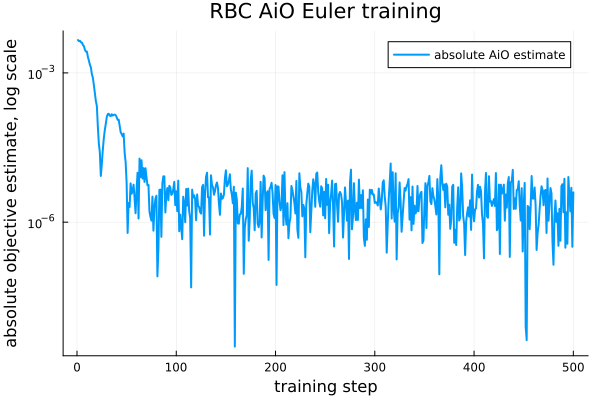

In [12]:
plot(abs.(result.loss_history) .+ 1e-16, yscale=:log10, lw=2, label="absolute AiO estimate")
xlabel!("training step")
ylabel!("absolute objective estimate, log scale")
title!("RBC AiO Euler training")

held-out test states = 2000 | shocks per state = 32 | seed = 99
median absolute Euler error = 1.1052e-03
p90 absolute Euler error = 2.6269e-03


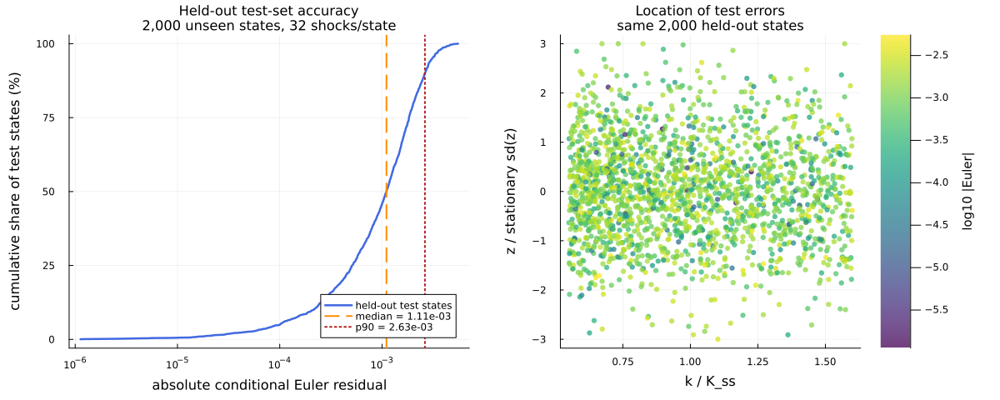

In [13]:
function conditional_euler_residual(theta, k, z, p::RBCParams, ss, rng::AbstractRNG; n_shocks=32)
    s = 0.0
    for _ in 1:n_shocks
        s += euler_draw_residual(theta, k, z, randn(rng), p, ss)
    end
    return s / n_shocks
end

function evaluate_residuals(theta, p::RBCParams, ss; n=2000, n_shocks=32, seed=99)
    rng = MersenneTwister(seed)
    k, z = sample_states(rng, n, p, ss)
    r = [conditional_euler_residual(theta, k[i], z[i], p, ss, rng; n_shocks=n_shocks) for i in 1:n]
    return r, k, z
end

test_size = 2000
test_shocks = 32
test_seed = 99
resid, k_eval, z_eval = evaluate_residuals(
    result.theta, par, ss; n=test_size, n_shocks=test_shocks, seed=test_seed
)
test_error = abs.(resid)
logerr = log10.(test_error .+ 1e-12)
median_error = median(test_error)
p90_error = quantile(test_error, 0.90)

@printf("held-out test states = %d | shocks per state = %d | seed = %d\n", test_size, test_shocks, test_seed)
@printf("median absolute Euler error = %.4e\n", median_error)
@printf("p90 absolute Euler error = %.4e\n", p90_error)

sorted_error = sort(test_error)
test_cdf = 100 .* collect(1:length(sorted_error)) ./ length(sorted_error)

p_ecdf = plot(
    sorted_error,
    test_cdf,
    xscale=:log10,
    lw=2.5,
    color=:royalblue,
    label="held-out test states",
    xlabel="absolute conditional Euler residual",
    ylabel="cumulative share of test states (%)",
    title="Held-out test-set accuracy\n2,000 unseen states, 32 shocks/state",
    titlefontsize=11,
    legend=:bottomright,
)
vline!(
    p_ecdf,
    [median_error],
    color=:darkorange,
    ls=:dash,
    lw=2,
    label=@sprintf("median = %.2e", median_error),
)
vline!(
    p_ecdf,
    [p90_error],
    color=:firebrick,
    ls=:dot,
    lw=2,
    label=@sprintf("p90 = %.2e", p90_error),
)

zsd = par.sigma_z / sqrt(1 - par.rho_z^2)
p_state = scatter(
    k_eval ./ ss.K,
    z_eval ./ zsd,
    marker_z=logerr,
    color=:viridis,
    ms=3.5,
    markerstrokewidth=0,
    alpha=0.75,
    label=false,
    xlabel="k / K_ss",
    ylabel="z / stationary sd(z)",
    colorbar_title="log10 |Euler|",
    title="Location of test errors\nsame 2,000 held-out states",
    titlefontsize=11,
)

test_diagnostics = plot(
    p_ecdf,
    p_state,
    layout=(1, 2),
    size=(1200, 480),
    left_margin=7Plots.mm,
    right_margin=6Plots.mm,
    bottom_margin=7Plots.mm,
    top_margin=4Plots.mm,
)

## 7.3) Policy Function: Neural Network vs. VFI and EGM

The figure below compares the neural-network policy learned from Euler-residual minimization with VFI and EGM numerical policy functions over their common capital interval $[k_{\min},k_{\max}]=[0.55K_{ss},1.60K_{ss}]$. Displaying the entire common interval makes any deterioration of the neural-network fit near the lower and upper boundaries visible directly in the policy functions.

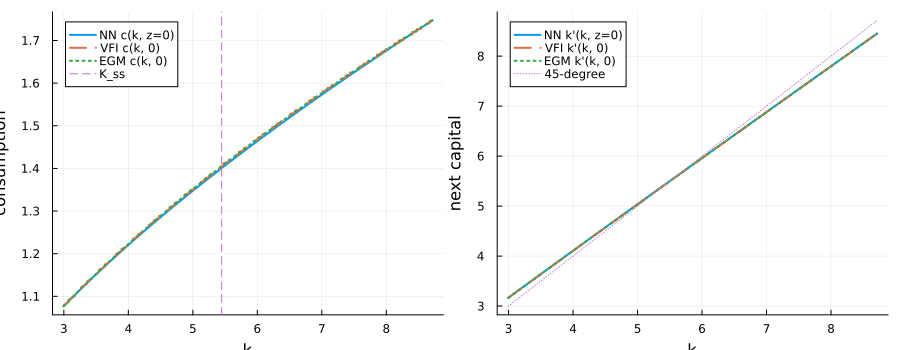

In [14]:
RBCNumericalSolvers.solve_vfi(par, ss; nk=warmup_nk, nz=warmup_nz, tol=Inf)
RBCNumericalSolvers.solve_egm(par, ss; nk=warmup_nk, nz=warmup_nz, tol=Inf)
GC.gc()

vfi_result = RBCNumericalSolvers.solve_vfi(par, ss;
    nk=nk, nz=nz, k_min=k_min_ratio * ss.K, k_max=k_max_ratio * ss.K,
    tol=vfi_tol, record_history=true)
GC.gc()
egm_result = RBCNumericalSolvers.solve_egm(par, ss;
    nk=nk, nz=nz, k_min=k_min_ratio * ss.K, k_max=k_max_ratio * ss.K,
    tol=egm_tol, record_history=true)

kgrid = vfi_result.kgrid
c_policy = [policy_ck(result.theta, k, 0.0, par, ss)[1] for k in kgrid]
kp_policy = [policy_ck(result.theta, k, 0.0, par, ss)[2] for k in kgrid]
kp_vfi = [RBCNumericalSolvers.interpolate_policy(vfi_result, k, 0.0) for k in kgrid]
kp_egm = [RBCNumericalSolvers.interpolate_policy(egm_result, k, 0.0) for k in kgrid]
c_vfi = [resources(k, 0.0, par) - kp for (k, kp) in zip(kgrid, kp_vfi)]
c_egm = [resources(k, 0.0, par) - kp for (k, kp) in zip(kgrid, kp_egm)]

p1 = plot(kgrid, c_policy, lw=2, label="NN c(k, z=0)", xlabel="k", ylabel="consumption")
plot!(p1, kgrid, c_vfi, lw=2, ls=:dash, label="VFI c(k, 0)")
plot!(p1, kgrid, c_egm, lw=2, ls=:dot, label="EGM c(k, 0)")
vline!(p1, [ss.K], label="K_ss", ls=:dash)
p2 = plot(kgrid, kp_policy, lw=2, label="NN k'(k, z=0)", xlabel="k", ylabel="next capital")
plot!(p2, kgrid, kp_vfi, lw=2, ls=:dash, label="VFI k'(k, 0)")
plot!(p2, kgrid, kp_egm, lw=2, ls=:dot, label="EGM k'(k, 0)")
plot!(p2, kgrid, kgrid, label="45-degree", ls=:dot)
plot(p1, p2, layout=(1, 2), size=(900, 350))

## 7.4) Common Test Euler MSE Across Solvers

The AiO history above is the stochastic training objective for the neural network. VFI and EGM have different native convergence criteria, so their iteration errors cannot be compared directly with the AiO estimate. To evaluate all three policy functions with the same economic restriction, fix a test set of states

$$
\mathcal T=\{(k_i,z_j):i=1,\ldots,N_k,\ j=1,\ldots,N_z\},
\qquad |\mathcal T|=N_kN_z.
$$

The test states are held fixed across algorithms and iterations and are not used to update the neural-network parameters. Let $\mathcal Z$ denote the finite set of productivity states. For a policy $\pi$, define the one-transition Euler residual at current test state $(k,z)$ and future productivity state $z'$ as

$$
q(k,z,z';\pi)
=
\beta
\frac{u'\!\left(c^\pi(k',z')\right)}
     {u'\!\left(c^\pi(k,z)\right)}
\left[\alpha e^{z'}(k')^{\alpha-1}+1-\delta\right]
-1,
\qquad
k'=k'^\pi(k,z).
$$

Using the same conditional transition probabilities for every method, the conditional Euler residual is

$$
\bar R(k,z;\pi)
=
\sum_{z'\in\mathcal Z}
P(z'\mid z)\,q(k,z,z';\pi).
$$

The common test metric simply averages the squared conditional residual over the fixed test set:

$$
\boxed{
\operatorname{MSE}(\pi)
=
\frac{1}{|\mathcal T|}
\sum_{(k,z)\in\mathcal T}
\bar R(k,z;\pi)^2.
}
$$

This is the same squared conditional Euler residual targeted by the population AiO objective. The difference is computational: AiO uses two independent future-shock draws to obtain an unbiased training estimator, whereas this test metric sums over all discrete future states and therefore has no future-shock Monte Carlo noise. It is used only for evaluation.

For VFI and EGM, the metric is recorded after every solver iteration. For the neural network, it is recorded at the first step and every ten AiO training steps. The first panel uses iteration or training step on the horizontal axis. The second panel uses cumulative solver or training time in seconds on a linear horizontal axis.

Each Julia code path is warmed up before timing. The cumulative time includes the numerical update for VFI and EGM and state sampling, gradient computation, the Adam update, and the reported AiO estimate for the neural network. JIT compilation, common-test MSE evaluation, and checkpoint copying are excluded. Wall-clock results remain specific to the current hardware and system load.

final common test Euler MSE, VFI = 1.018529e-05
final common test Euler MSE, EGM = 1.808421e-15
final common test Euler MSE, NN  = 3.398713e-07
cumulative computation time, VFI = 12.2477 seconds
cumulative computation time, EGM = 1.6552 seconds
cumulative computation time, NN  = 28.4678 seconds


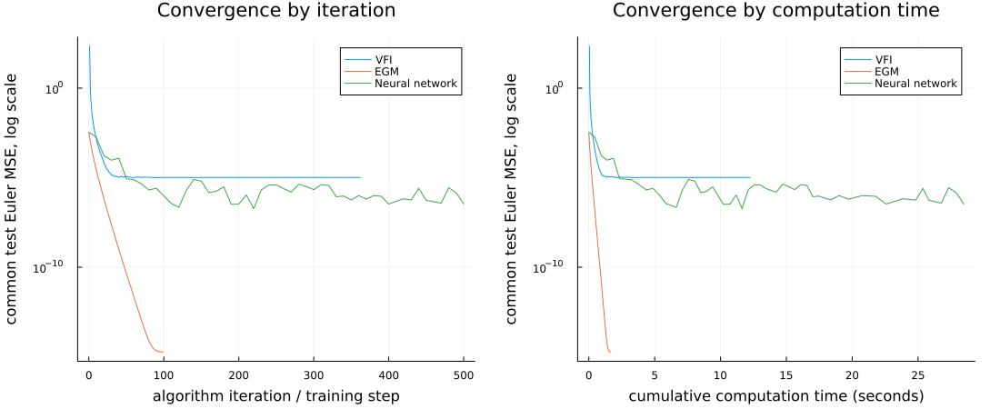

In [15]:
test_kgrid = collect(range(0.60 * ss.K, 1.50 * ss.K, length=80))
test_zgrid = vfi_result.zgrid
test_P = vfi_result.P

vfi_test_mse = [
    RBCNumericalSolvers.test_euler_mse(
        policy_kp, vfi_result.kgrid, test_zgrid, test_P, par; k_test=test_kgrid
    )
    for policy_kp in vfi_result.policy_history
]

egm_test_mse = [
    RBCNumericalSolvers.test_euler_mse(
        policy_kp, egm_result.kgrid, test_zgrid, test_P, par; k_test=test_kgrid
    )
    for policy_kp in egm_result.policy_history
]

nn_test_iterations = unique(vcat(
    [1], collect(10:10:length(result.theta_history)), [length(result.theta_history)]
))
nn_test_time = result.time_history[nn_test_iterations]
nn_test_mse = Float64[]
for iteration in nn_test_iterations
    theta_checkpoint = result.theta_history[iteration]
    nn_policy = function (k, z)
        c, kp, _ = policy_ck(theta_checkpoint, k, z, par, ss)
        return c, kp
    end
    push!(nn_test_mse,
        RBCNumericalSolvers.test_euler_mse(nn_policy, test_kgrid, test_zgrid, test_P, par))
end

@printf("final common test Euler MSE, VFI = %.6e\n", vfi_test_mse[end])
@printf("final common test Euler MSE, EGM = %.6e\n", egm_test_mse[end])
@printf("final common test Euler MSE, NN  = %.6e\n", nn_test_mse[end])
@printf("cumulative computation time, VFI = %.4f seconds\n", vfi_result.time_history[end])
@printf("cumulative computation time, EGM = %.4f seconds\n", egm_result.time_history[end])
@printf("cumulative computation time, NN  = %.4f seconds\n", nn_test_time[end])

p_iteration = plot(yscale=:log10, lw=2,
    xlabel="algorithm iteration / training step",
    ylabel="common test Euler MSE, log scale",
    title="Convergence by iteration",
    legend=:topright)
plot!(p_iteration, vfi_result.iteration_history, max.(vfi_test_mse, 1e-16), label="VFI")
plot!(p_iteration, egm_result.iteration_history, max.(egm_test_mse, 1e-16), label="EGM")
plot!(p_iteration, nn_test_iterations, max.(nn_test_mse, 1e-16), label="Neural network")

p_time = plot(yscale=:log10, lw=2,
    xlabel="cumulative computation time (seconds)",
    ylabel="common test Euler MSE, log scale",
    title="Convergence by computation time",
    legend=:topright)
plot!(p_time, vfi_result.time_history, max.(vfi_test_mse, 1e-16), label="VFI")
plot!(p_time, egm_result.time_history, max.(egm_test_mse, 1e-16), label="EGM")
plot!(p_time, nn_test_time, max.(nn_test_mse, 1e-16), label="Neural network")

p_test = plot(p_iteration, p_time, layout=(1, 2), size=(1100, 450), margin=5Plots.mm)
p_test

## 8) Simulation-generated current states

The baseline network above uses **direct sampling**: every training iteration independently draws current states from the full capital interval and a truncated stationary Gaussian distribution for productivity. This section keeps the same RBC model, neural network, AiO objective, Adam settings, initialization, batch size, and number of training steps, and changes only the distribution of **current training states**.

We compare three training schemes:

1. **Direct sampling:** the existing `result`, with independent state draws from `sample_states`.
2. **Pure simulation:** a pool of economies is advanced under the current neural-network policy, and all current training states come from this on-policy particle simulation.
3. **Simulation + 20% full-box exploration:** 80% of every batch comes from the particle simulation, while 20% is drawn uniformly over the complete common state rectangle,

$$
\log k\sim U\!\left(\log(0.55K_{ss}),\log(1.60K_{ss})\right),
\qquad
z\sim U\!\left(-3\sigma_{z,\infty},3\sigma_{z,\infty}\right).
$$

The full-box component replaces the cross-shaped tail sampler in the original notebook. It gives positive sampling support to the corners where capital and productivity are simultaneously extreme. In all three schemes, the two conditionally independent future shocks required by the AiO estimator are still drawn in exactly the same way as before.


In [16]:
function advance_particles!(theta, k, z, rng::AbstractRNG, p::RBCParams, ss)
    kp_new = similar(k)
    z_new = similar(z)
    for i in eachindex(k)
        _, kp_new[i], _ = policy_ck(theta, k[i], z[i], p, ss)
        z_new[i] = p.rho_z * z[i] + p.sigma_z * randn(rng)
    end
    k .= kp_new
    z .= z_new
    return nothing
end

function initialize_particle_states(theta, rng::AbstractRNG, n::Int, p::RBCParams, ss; burnin=100)
    k = fill(ss.K, n)
    z = zeros(n)
    for _ in 1:burnin
        advance_particles!(theta, k, z, rng, p, ss)
    end
    return k, z
end

function sample_full_box_states(rng::AbstractRNG, n::Int, p::RBCParams, ss)
    zsd = p.sigma_z / sqrt(1 - p.rho_z^2)
    log_k_min = log(k_min_ratio * ss.K)
    log_k_max = log(k_max_ratio * ss.K)
    k = exp.(log_k_min .+ (log_k_max - log_k_min) .* rand(rng, n))
    z = 3zsd .* (2 .* rand(rng, n) .- 1)
    return k, z
end

function train_simulation!(theta, p::RBCParams, ss; steps=500, batch_size=256, lr=0.01,
        seed=2026, exploration_share=0.0, burnin=100, trace_every=10,
        display_step=100, verbose=true)
    transition_rng = MersenneTwister(seed)
    batch_rng = MersenneTwister(seed + 1)
    shock_rng = MersenneTwister(seed + 2)
    sim_k, sim_z = initialize_particle_states(
        theta, transition_rng, batch_size, p, ss; burnin=burnin
    )
    opt = AdamState(length(theta))
    loss_history = Float64[]
    time_history = Float64[]
    trace_k = Float64[]
    trace_z = Float64[]
    elapsed_time = 0.0
    n_explore = round(Int, exploration_share * batch_size)
    n_sim = batch_size - n_explore

    for it in 1:steps
        iteration_start = time_ns()
        if n_explore == 0
            k_batch = copy(sim_k)
            z_batch = copy(sim_z)
        else
            sim_idx = randperm(batch_rng, batch_size)[1:n_sim]
            explore_k, explore_z = sample_full_box_states(batch_rng, n_explore, p, ss)
            k_batch = vcat(sim_k[sim_idx], explore_k)
            z_batch = vcat(sim_z[sim_idx], explore_z)
        end

        eps_1_batch = randn(shock_rng, batch_size)
        eps_2_batch = randn(shock_rng, batch_size)
        lossfun = th -> aio_euler_loss(
            th, k_batch, z_batch, eps_1_batch, eps_2_batch, p, ss
        )
        grad = ad_gradient(theta, lossfun)
        adam_step!(theta, grad, opt; lr=lr)
        push!(loss_history, lossfun(theta))
        elapsed_time += (time_ns() - iteration_start) / 1e9
        push!(time_history, elapsed_time)

        if it % trace_every == 0
            append!(trace_k, k_batch)
            append!(trace_z, z_batch)
        end
        advance_particles!(theta, sim_k, sim_z, transition_rng, p, ss)

        if verbose && (it == 1 || it % display_step == 0)
            @printf(
                "step %5d | AiO estimate %.6e | mean(k/K_ss) %.4f | exploration share %.2f\n",
                it, loss_history[end], mean(sim_k) / ss.K, exploration_share
            )
        end
    end

    return (; theta, loss_history, time_history, trace_k, trace_z, sim_k, sim_z)
end


train_simulation! (generic function with 1 method)

step     1 | AiO estimate 3.096116e-05 | mean(k/K_ss) 0.9995 | exploration share 0.00
step   100 | AiO estimate -2.173690e-06 | mean(k/K_ss) 0.9970 | exploration share 0.00
step   200 | AiO estimate -7.744002e-07 | mean(k/K_ss) 0.9969 | exploration share 0.00
step   300 | AiO estimate -1.585105e-06 | mean(k/K_ss) 1.0021 | exploration share 0.00
step   400 | AiO estimate 1.271245e-06 | mean(k/K_ss) 1.0019 | exploration share 0.00
step   500 | AiO estimate 1.466437e-06 | mean(k/K_ss) 1.0004 | exploration share 0.00
step     1 | AiO estimate 8.396439e-04 | mean(k/K_ss) 0.9995 | exploration share 0.20
step   100 | AiO estimate -2.406421e-06 | mean(k/K_ss) 0.9986 | exploration share 0.20
step   200 | AiO estimate -5.936017e-07 | mean(k/K_ss) 0.9990 | exploration share 0.20
step   300 | AiO estimate -2.742037e-06 | mean(k/K_ss) 1.0025 | exploration share 0.20
step   400 | AiO estimate 2.205837e-06 | mean(k/K_ss) 1.0032 | exploration share 0.20
step   500 | AiO estimate 2.206402e-06 | mean(k/

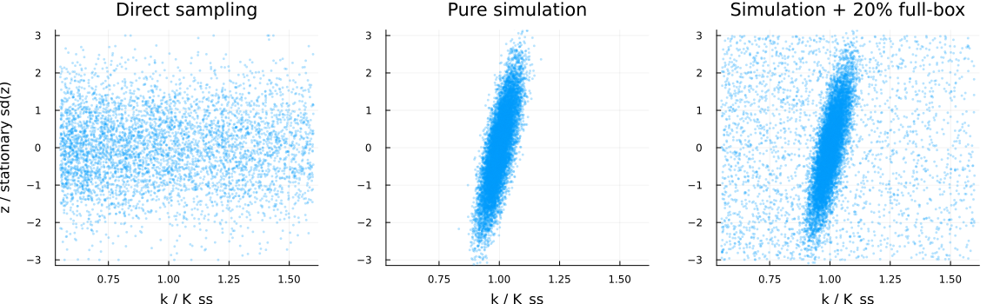

In [17]:
# The baseline `result` above already used the same initialization and training settings.
theta0 = init_theta(MersenneTwister(1234), par, ss)

simulation_result = train_simulation!(copy(theta0), par, ss;
    steps=500, batch_size=256, lr=0.01, seed=2026,
    exploration_share=0.0, display_step=100)

mixed_result = train_simulation!(copy(theta0), par, ss;
    steps=500, batch_size=256, lr=0.01, seed=2026,
    exploration_share=0.20, display_step=100)

coverage_rng = MersenneTwister(7070)
direct_k, direct_z = sample_states(coverage_rng, 5000, par, ss)
zsd = par.sigma_z / sqrt(1 - par.rho_z^2)

coverage_style = (
    ms=1.6, alpha=0.28, markerstrokewidth=0, label=false,
    xlim=(k_min_ratio - 0.02, k_max_ratio + 0.02), ylim=(-3.15, 3.15),
    xlabel="k / K_ss",
)
p_direct = scatter(direct_k ./ ss.K, direct_z ./ zsd;
    coverage_style..., ylabel="z / stationary sd(z)", title="Direct sampling")
p_simulation = scatter(simulation_result.trace_k ./ ss.K,
    simulation_result.trace_z ./ zsd;
    coverage_style..., title="Pure simulation")
p_mixed = scatter(mixed_result.trace_k ./ ss.K, mixed_result.trace_z ./ zsd;
    coverage_style..., title="Simulation + 20% full-box")

training_coverage = plot(
    p_direct, p_simulation, p_mixed,
    layout=(1, 3), size=(1150, 350), margin=4Plots.mm
)
training_coverage


### 8.1 Common held-out evaluation

The training loss is a noisy mini-batch AiO estimate, so it is not used to rank the final networks. Instead, the three trained policies are evaluated with identical held-out states and identical future shocks. We report results for both:

- a **baseline-shaped test set**, drawn by the baseline `sample_states`; and
- a **full-box stress test**, drawn uniformly in the plotted coordinates over the entire common state rectangle: $k/K_{ss}\sim U(0.55,1.60)$ and $z/\sigma_{z,\infty}\sim U(-3,3)$.

For every held-out state, 64 future shocks approximate the conditional Euler residual. Lower median, p90, and mean squared conditional residual indicate a more accurate policy.


In [ ]:
function conditional_residuals_common_shocks(theta, k, z, eps, p::RBCParams, ss)
    out = Vector{Float64}(undef, length(k))
    for i in eachindex(k)
        out[i] = mean(
            euler_draw_residual(theta, k[i], z[i], eps[i, j], p, ss)
            for j in axes(eps, 2)
        )
    end
    return out
end

function sample_uniform_test_box_states(rng::AbstractRNG, n::Int, p::RBCParams, ss)
    zsd = p.sigma_z / sqrt(1 - p.rho_z^2)
    k = ss.K .* (k_min_ratio .+ (k_max_ratio - k_min_ratio) .* rand(rng, n))
    z = zsd .* (-3 .+ 6 .* rand(rng, n))
    return k, z
end

baseline_test_k, baseline_test_z = sample_states(
    MersenneTwister(8080), 2000, par, ss
)
fullbox_test_k, fullbox_test_z = sample_uniform_test_box_states(
    MersenneTwister(8081), 2000, par, ss
)
baseline_test_eps = randn(MersenneTwister(9090), length(baseline_test_k), 64)
fullbox_test_eps = randn(MersenneTwister(9091), length(fullbox_test_k), 64)

training_models = [
    (name="Direct sampling", theta=result.theta, color=:royalblue, linestyle=:solid),
    (name="Pure simulation", theta=simulation_result.theta, color=:darkorange, linestyle=:dash),
    (name="Simulation + exploration", theta=mixed_result.theta, color=:seagreen, linestyle=:dot),
]
evaluation_sets = [
    (name="baseline-shaped", k=baseline_test_k, z=baseline_test_z,
        eps=baseline_test_eps),
    (name="full-box stress", k=fullbox_test_k, z=fullbox_test_z,
        eps=fullbox_test_eps),
]

simulation_summary = NamedTuple[]
fullbox_errors = Dict{String, Vector{Float64}}()
for evaluation in evaluation_sets
    for model in training_models
        residual = conditional_residuals_common_shocks(
            model.theta, evaluation.k, evaluation.z, evaluation.eps, par, ss
        )
        error = abs.(residual)
        push!(simulation_summary, (
            method=model.name,
            test_set=evaluation.name,
            median=median(error),
            p90=quantile(error, 0.90),
            mse=mean(residual .^ 2),
        ))
        if evaluation.name == "full-box stress"
            fullbox_errors[model.name] = error
        end
    end
end

@printf("%-26s %-19s %13s %13s %13s\n",
    "training states", "held-out states", "median", "p90", "Euler MSE")
for row in simulation_summary
    @printf("%-26s %-19s %13.4e %13.4e %13.4e\n",
        row.method, row.test_set, row.median, row.p90, row.mse)
end

p_fullbox_ecdf = plot(
    xscale=:log10,
    xlabel="absolute conditional Euler residual",
    ylabel="cumulative share of held-out states (%)",
    title="Uniform full-box held-out stress test\n2,000 unseen states, 64 shocks/state",
    legend=:bottomright,
    size=(720, 440),
    margin=5Plots.mm,
)
for model in training_models
    fullbox_sorted_error = sort(fullbox_errors[model.name] .+ 1e-12)
    cdf = 100 .* collect(1:length(fullbox_sorted_error)) ./ length(fullbox_sorted_error)
    plot!(p_fullbox_ecdf, fullbox_sorted_error, cdf,
        color=model.color, ls=model.linestyle, lw=2.4, label=model.name)
end
p_fullbox_ecdf


### 8.2 Policy functions: three training distributions versus EGM

The final comparison uses the complete EGM solver capital grid and sets $z=0$. The first two panels show the consumption and next-capital policies in normalized units. The third panel magnifies each neural network's absolute next-capital difference from EGM, making small discrepancies visible even when the policy curves overlap.


training states             mean |k' gap|/Kss   max |k' gap|/Kss
Direct sampling                    5.3490e-04         8.2107e-04
Pure simulation                    3.5155e-03         1.0111e-02
Simulation + exploration           4.0919e-04         9.8640e-04


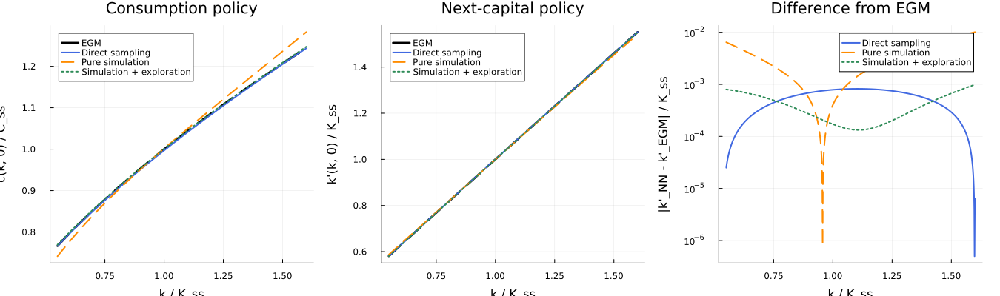

In [22]:
policy_kgrid = egm_result.kgrid
policy_x = policy_kgrid ./ ss.K
kp_egm_simulation = [
    RBCNumericalSolvers.interpolate_policy(egm_result, k, 0.0)
    for k in policy_kgrid
]
c_egm_simulation = [
    resources(k, 0.0, par) - kp
    for (k, kp) in zip(policy_kgrid, kp_egm_simulation)
]

p_c_simulation = plot(
    policy_x, c_egm_simulation ./ ss.C,
    color=:black, ls=:dash, lw=2.8, label="EGM",
    xlabel="k / K_ss", ylabel="c(k, 0) / C_ss",
    title="Consumption policy", legend=:topleft,
)
p_kp_simulation = plot(
    policy_x, kp_egm_simulation ./ ss.K,
    color=:black, ls=:dash, lw=2.8, label="EGM",
    xlabel="k / K_ss", ylabel="k'(k, 0) / K_ss",
    title="Next-capital policy", legend=:topleft,
)
p_gap_simulation = plot(
    yscale=:log10,
    xlabel="k / K_ss", ylabel="|k'_NN - k'_EGM| / K_ss",
    title="Difference from EGM", legend=:topright,
)

@printf("%-26s %18s %18s\n", "training states", "mean |k' gap|/Kss", "max |k' gap|/Kss")
for model in training_models
    c_nn = [policy_ck(model.theta, k, 0.0, par, ss)[1] for k in policy_kgrid]
    kp_nn = [policy_ck(model.theta, k, 0.0, par, ss)[2] for k in policy_kgrid]
    kp_gap = abs.(kp_nn .- kp_egm_simulation) ./ ss.K
    @printf("%-26s %18.4e %18.4e\n", model.name, mean(kp_gap), maximum(kp_gap))
    plot!(p_c_simulation, policy_x, c_nn ./ ss.C,
        color=model.color, ls=model.linestyle, lw=2.0, label=model.name)
    plot!(p_kp_simulation, policy_x, kp_nn ./ ss.K,
        color=model.color, ls=model.linestyle, lw=2.0, label=model.name)
    plot!(p_gap_simulation, policy_x, max.(kp_gap, 1e-12),
        color=model.color, ls=model.linestyle, lw=2.0, label=model.name)
end

simulation_policy_comparison = plot(
    p_c_simulation, p_kp_simulation, p_gap_simulation,
    layout=(1, 3), size=(1350, 400), margin=4Plots.mm
)
simulation_policy_comparison


### 8.3 Where are the test errors located?

The next figure uses the **same 2,000 held-out states and the same 64 future shocks per state** for all three networks. To give every part of the displayed rectangle equal representation, the test states are uniform in the plotted coordinates,

$$
\frac{k}{K_{ss}}\sim U(0.55,1.60),
\qquad
\frac{z}{\sigma_{z,\infty}}\sim U(-3,3).
$$

Point color is $\log_{10}|\text{conditional Euler residual}|$. The panels use one common color scale, so both the spatial pattern and the error magnitude are directly comparable across training methods. Yellow points have larger Euler errors; dark-purple points have smaller errors.


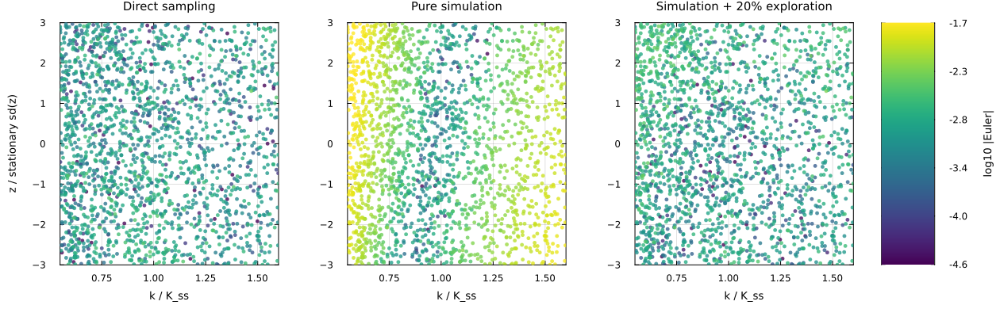

In [21]:
fullbox_log_errors = Dict(
    model.name => log10.(fullbox_errors[model.name] .+ 1e-12)
    for model in training_models
)

# A robust shared scale prevents a few extreme points from washing out the spatial pattern.
all_fullbox_log_errors = vcat([fullbox_log_errors[model.name] for model in training_models]...)
error_color_limits = (
    quantile(all_fullbox_log_errors, 0.01),
    quantile(all_fullbox_log_errors, 0.99),
)

# All three data panels use identical margins and no internal colorbar.
error_location_panels = Any[]
for (panel_index, model) in enumerate(training_models)
    log_error = fullbox_log_errors[model.name]
    draw_order = sortperm(log_error)  # draw high-error states last so they remain visible
    panel_title = model.name == "Simulation + exploration" ?
        "Simulation + 20% exploration" : model.name
    panel = scatter(
        fullbox_test_k[draw_order] ./ ss.K,
        fullbox_test_z[draw_order] ./ zsd,
        marker_z=log_error[draw_order],
        color=:viridis,
        clims=error_color_limits,
        colorbar=false,
        ms=2.7,
        alpha=0.78,
        markerstrokewidth=0,
        label=false,
        xlim=(k_min_ratio, k_max_ratio),
        ylim=(-3.0, 3.0),
        xlabel="k / K_ss",
        ylabel=panel_index == 1 ? "z / stationary sd(z)" : "",
        title=panel_title,
        titlefontsize=10,
        tickfontsize=8,
        guidefontsize=9,
        gridalpha=0.12,
        framestyle=:box,
        left_margin=7Plots.mm,
        right_margin=3Plots.mm,
        top_margin=3Plots.mm,
        bottom_margin=7Plots.mm,
    )
    push!(error_location_panels, panel)
end

# The shared color scale is a separate fourth column, so it cannot shrink the third panel.
scale_values = collect(range(error_color_limits[1], error_color_limits[2], length=256))
scale_matrix = repeat(reshape(scale_values, :, 1), 1, 2)
scale_ticks = collect(range(error_color_limits[1], error_color_limits[2], length=6))
shared_error_color_scale = heatmap(
    [0.0, 1.0], scale_values, scale_matrix,
    color=:viridis,
    clims=error_color_limits,
    colorbar=false,
    xticks=false,
    xaxis=false,
    yticks=(scale_ticks, string.(round.(scale_ticks, digits=1))),
    ylabel="log10 |Euler|",
    mirror=true,
    yguide_position=:right,
    tickfontsize=8,
    guidefontsize=9,
    grid=false,
    framestyle=:box,
    left_margin=2Plots.mm,
    right_margin=7Plots.mm,
    top_margin=3Plots.mm,
    bottom_margin=7Plots.mm,
)

diagnostic_layout = @layout [a b c d{0.075w}]
error_location_diagnostic = plot(
    error_location_panels...,
    shared_error_color_scale,
    layout=diagnostic_layout,
    size=(1260, 390),
)
error_location_diagnostic


Because pure simulation generates few observations far from the steady state, those regions are under-trained; mixing in a small share of full-box samples improves their training coverage while keeping the batch size and computational burden essentially unchanged.
